# Лабораторная работа 3 Регрессионный анализ

Жойд Станислав Вадимович, группа 4417, вариант 8. Дисциплина «Анализ данных».

Цель работы - изучить на практике алгоритмы регрессии, сравнить качество моделей и объяснить полученные результаты.

Используются лист `var8` файла `regression.xlsx` и таблица `salary.csv`. Для повторного запуска файлы `regression.xlsx` и `salary.csv` нужно поместить в папку `utility` рядом с ноутбуком. Все преобразования обучаются только по тренировочным данным. Разбиение воспроизводится с `random_state=8`, соответствующим номеру варианта.

In [ ]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown, Image
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor

SEED = 8
U = Path('utility')
FIG = U / 'figures'
RES = U / 'results'
FIG.mkdir(parents=True, exist_ok=True)
RES.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:.5f}'.format)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.2})

def savefig(name):
    plt.gcf().savefig(FIG / name, dpi=300, bbox_inches='tight')
    display(Image(filename=str(FIG / name)))
    plt.close()

def metrics(y, prediction):
    return {'MAE': mean_absolute_error(y, prediction),
            'MSE': mean_squared_error(y, prediction),
            'RMSE': np.sqrt(mean_squared_error(y, prediction)),
            'R2': r2_score(y, prediction)}

def fact_prediction(ax, y, prediction, title):
    ax.scatter(y, prediction, s=13, alpha=0.6)
    limits = [min(np.min(y), np.min(prediction)), max(np.max(y), np.max(prediction))]
    ax.plot(limits, limits, color='red', label='Идеальный прогноз')
    ax.set(xlabel='Фактическое значение', ylabel='Прогноз', title=title, xlim=limits, ylim=limits)
    ax.set_aspect('equal', adjustable='box')
    ax.legend(fontsize=8)

versions = {'Python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__}
print(versions)

# 1 Простая линейная регрессия

## 1.1 Исходные данные и корреляции

Загружен лист `var8`. Функция `describe()` показывает объём выборки, средние значения, разброс и квартили. Корреляция Пирсона оценивает только линейную связь и не доказывает причинность.

In [2]:
reg = pd.read_excel(U / 'regression.xlsx', sheet_name='var8')
display(reg.head())
display(reg.describe())
display(reg.corr(method='pearson'))
print('Пропуски:', reg.isna().sum().to_dict())
print('Дубликаты:', int(reg.duplicated().sum()))
reg.describe().to_csv(RES / 'regression_describe.csv')
reg.corr().to_csv(RES / 'regression_correlations.csv')

,x1,x2,y
0,-1.65571,1.20458,2.77791
1,-0.46174,1.49421,0.59487
2,0.82342,-1.02407,-1.41403
3,0.90086,0.44011,0.10488
4,0.51141,-1.75304,-1.38714


,x1,x2,y
count,1000.00000,1000.00000,1000.00000
mean,-0.00002,-0.00001,0.41062
std,1.15525,1.15528,1.06084
min,-1.99730,-1.99732,-2.24819
25%,-0.99969,-0.99805,-0.38055
50%,0.00050,0.00092,0.36008
75%,0.99961,0.99893,1.15656
max,1.99721,1.99956,4.07737


,x1,x2,y
x1,1.00000,-0.01499,-0.33370
x2,-0.01499,1.00000,0.59327
y,-0.33370,0.59327,1.00000


Пропуски: {'x1': 0, 'x2': 0, 'y': 0}
Дубликаты: 0


Коэффициент корреляции x1 с y равен −0,33370: линейная связь отрицательная и сравнительно слабая. Для x2 получено 0,59327: положительная связь выражена сильнее. Между x1 и x2 почти нет линейной связи (−0,01499). По одному коэффициенту корреляции нельзя исключить нелинейную зависимость.

## 1.2 Обучение моделей и оценка

Для обеих моделей использовано одно разбиение: 75% наблюдений для обучения и 25% для проверки. Модель имеет вид y = a·x + b. MAE измеряет среднюю абсолютную ошибку, MSE - средний квадрат ошибки, RMSE выражает ошибку в единицах y. R² сравнивает сумму квадратов ошибок с разбросом фактических значений; отрицательный R² означает качество хуже постоянного прогноза среднего проверочной выборки.

In [3]:
train_idx, valid_idx = train_test_split(reg.index, test_size=0.25, random_state=SEED)
simple_models = {}
simple_rows = []
simple_predictions = pd.DataFrame({'y': reg.loc[valid_idx, 'y']})
for feature in ['x1', 'x2']:
    model = LinearRegression()
    model.fit(reg.loc[train_idx, [feature]], reg.loc[train_idx, 'y'])
    prediction = model.predict(reg.loc[valid_idx, [feature]])
    simple_models[feature] = model
    simple_predictions[feature] = prediction
    simple_rows.append({'Признак': feature, 'a': model.coef_[0], 'b': model.intercept_, **metrics(reg.loc[valid_idx, 'y'], prediction)})
    comparison = pd.DataFrame({'Факт': reg.loc[valid_idx, 'y'], 'Прогноз': prediction, 'Прогноз минус факт': prediction - reg.loc[valid_idx, 'y']})
    display(comparison)
    comparison.to_csv(RES / f'simple_predictions_{feature}.csv', index_label='Индекс')
simple_metrics = pd.DataFrame(simple_rows)
display(simple_metrics)
print('Обучение:', len(train_idx), 'Проверка:', len(valid_idx))
simple_metrics.to_csv(RES / 'simple_metrics.csv', index=False)

,Факт,Прогноз,Прогноз минус факт
908,-1.14724,0.53743,1.68467
265,0.19670,0.46151,0.26481
627,1.16416,0.35498,-0.80918
327,0.90556,0.19250,-0.71306
244,-0.09743,0.62243,0.71986
...,...,...,...
288,-0.92302,0.30298,1.22600
335,1.80301,0.56913,-1.23388
510,1.54253,0.42128,-1.12125
836,0.29990,0.16106,-0.13884


,Факт,Прогноз,Прогноз минус факт
908,-1.14724,-0.49108,0.65616
265,0.19670,0.86284,0.66613
627,1.16416,1.40326,0.23910
327,0.90556,1.15350,0.24794
244,-0.09743,1.09700,1.19443
...,...,...,...
288,-0.92302,0.21333,1.13635
335,1.80301,1.49490,-0.30812
510,1.54253,1.42229,-0.12023
836,0.29990,0.66376,0.36386


,Признак,a,b,MAE,MSE,RMSE,R2
0,x1,-0.29034,0.40123,0.79922,0.93202,0.96541,0.14942
1,x2,0.54915,0.39972,0.66122,0.72872,0.85365,0.33495


Обучение: 750 Проверка: 250


## 1.3 Графики и ошибки

На первом рисунке представлены наблюдения и прямые, обученные на тренировочной выборке. Затем показана разность «прогноз − факт» для каждой проверочной точки. На графиках факт-прогноз красная диагональ обозначает идеальное совпадение. Одинаковые пределы и масштаб осей сохраняют угол 45°.

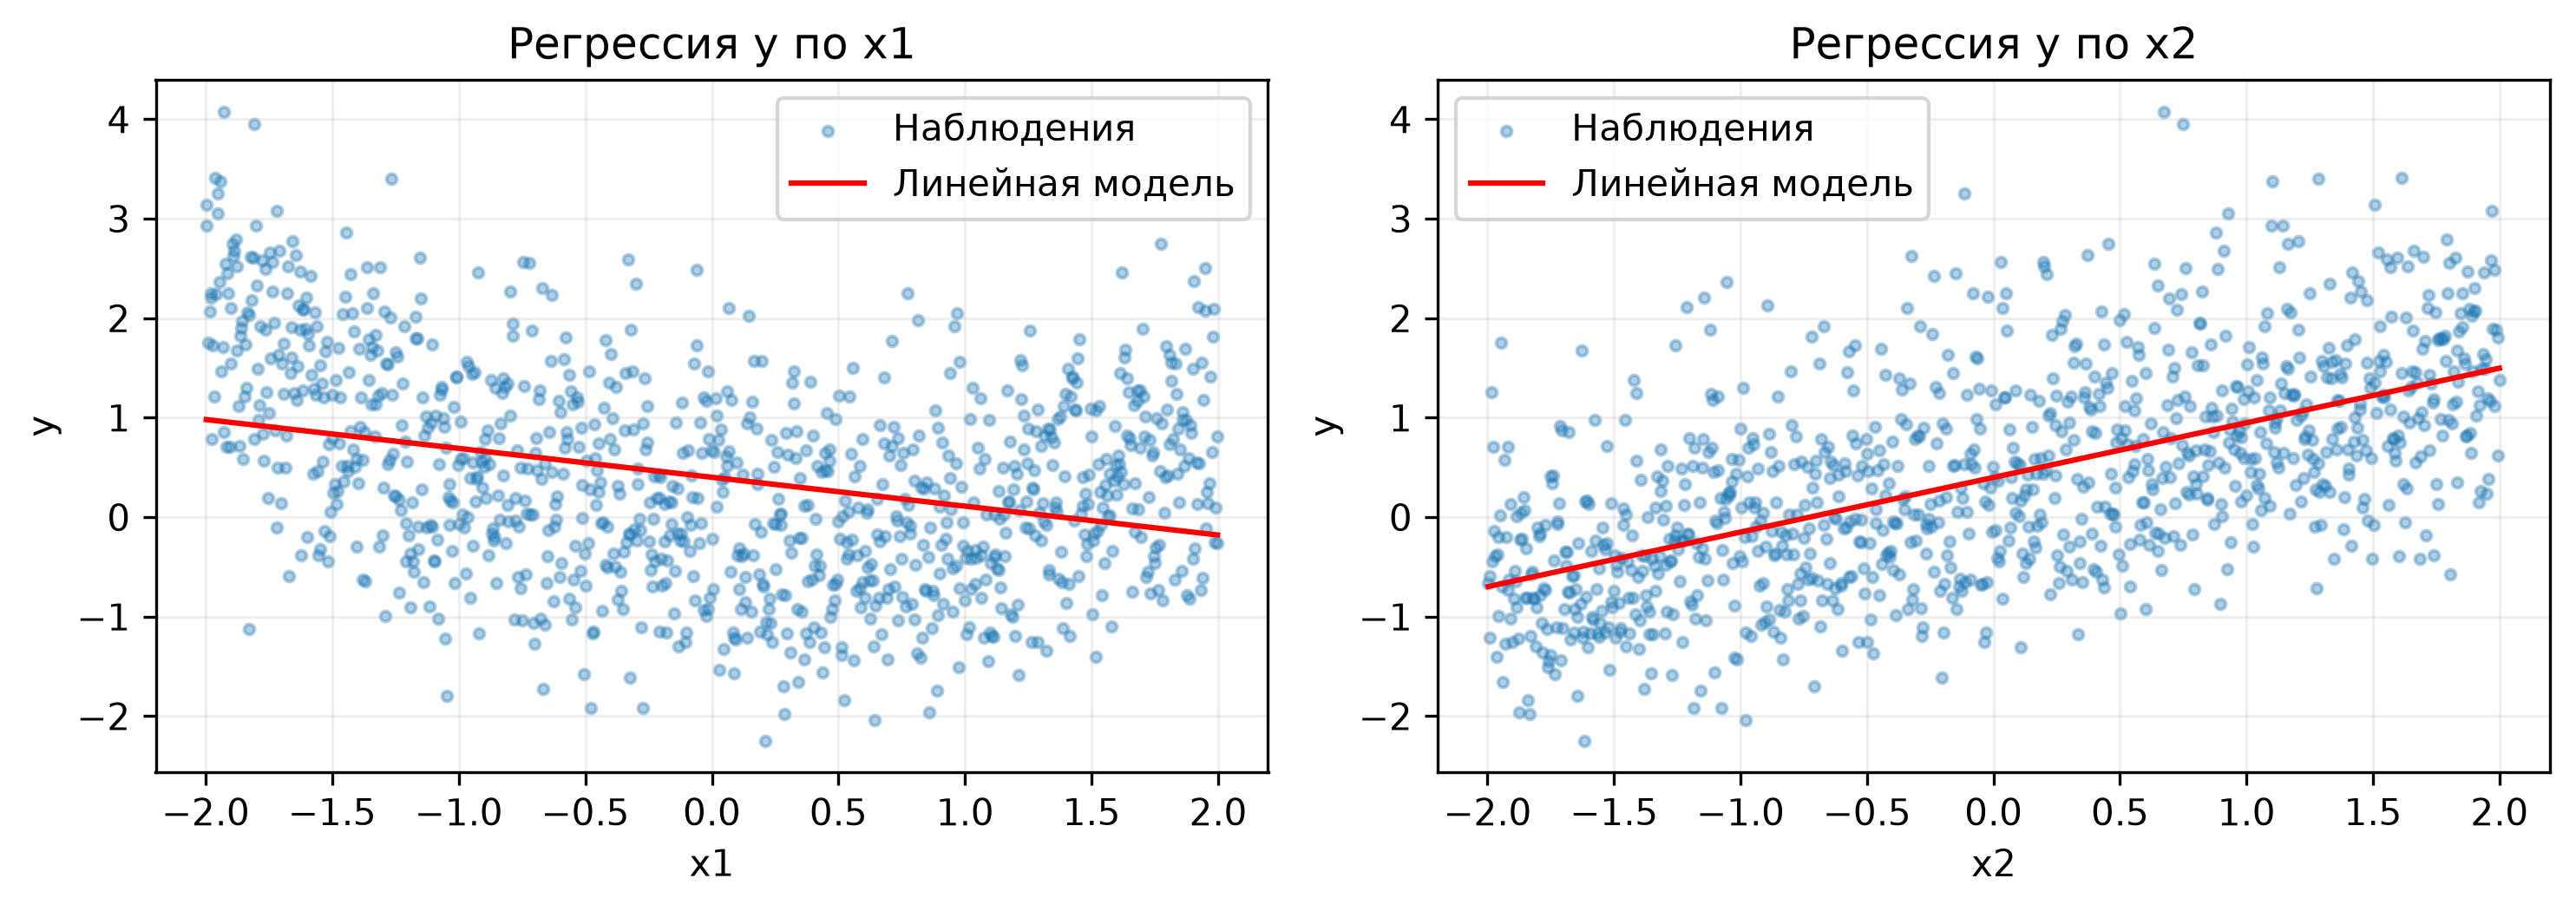

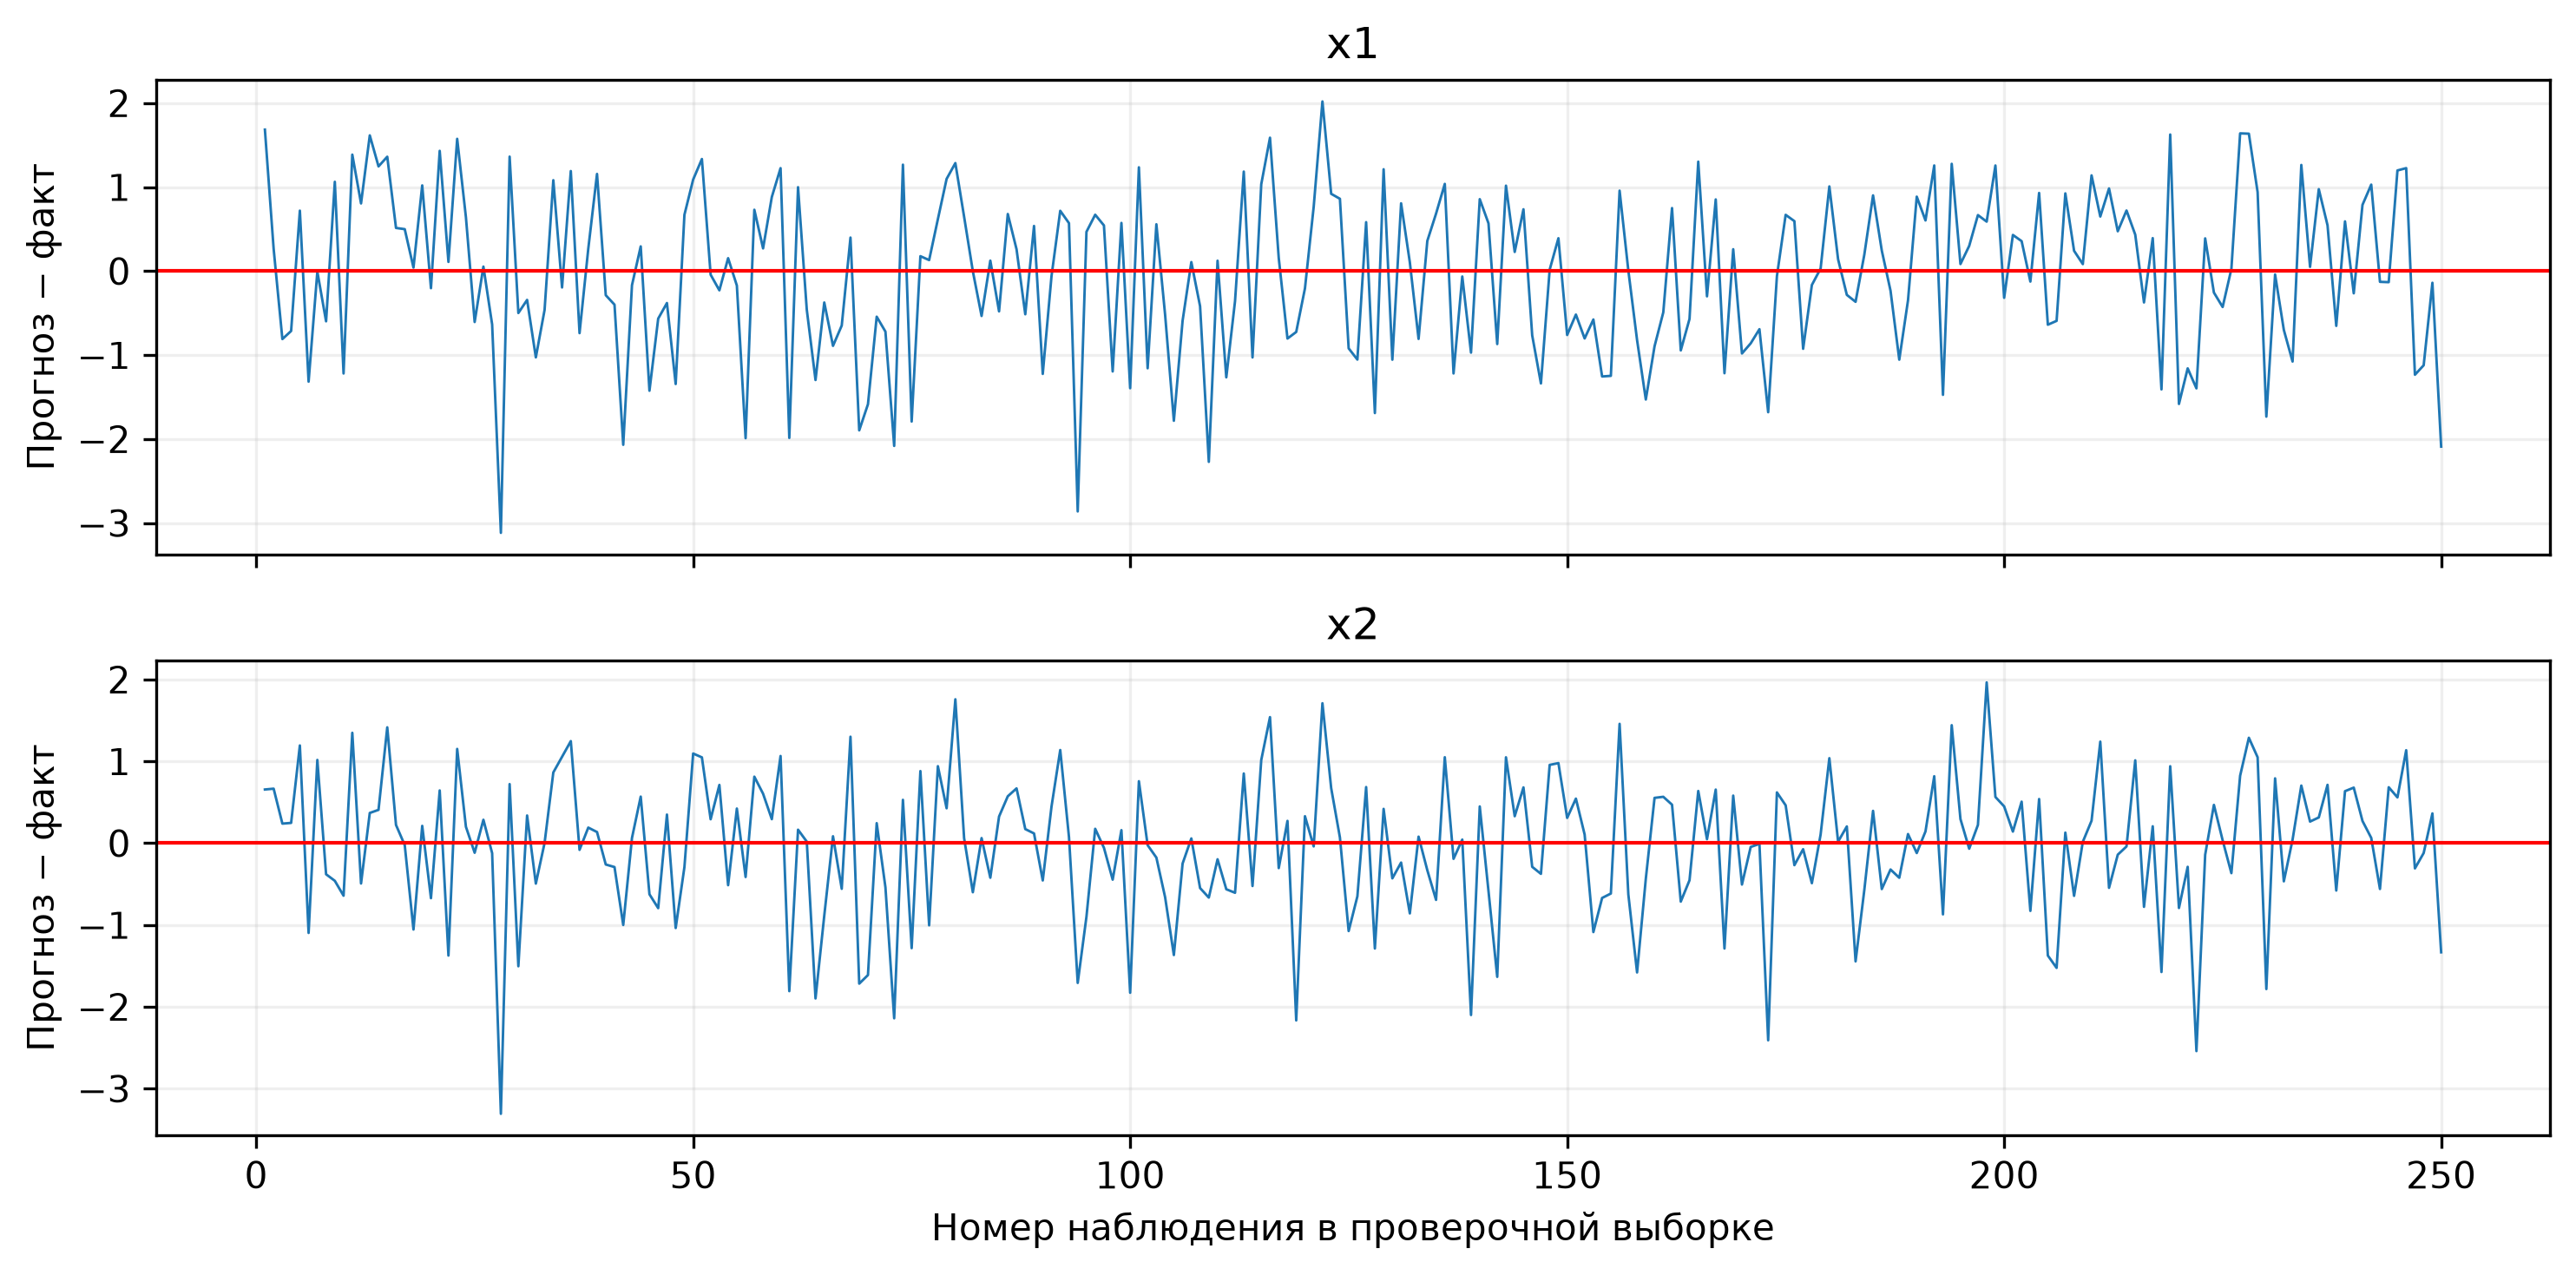

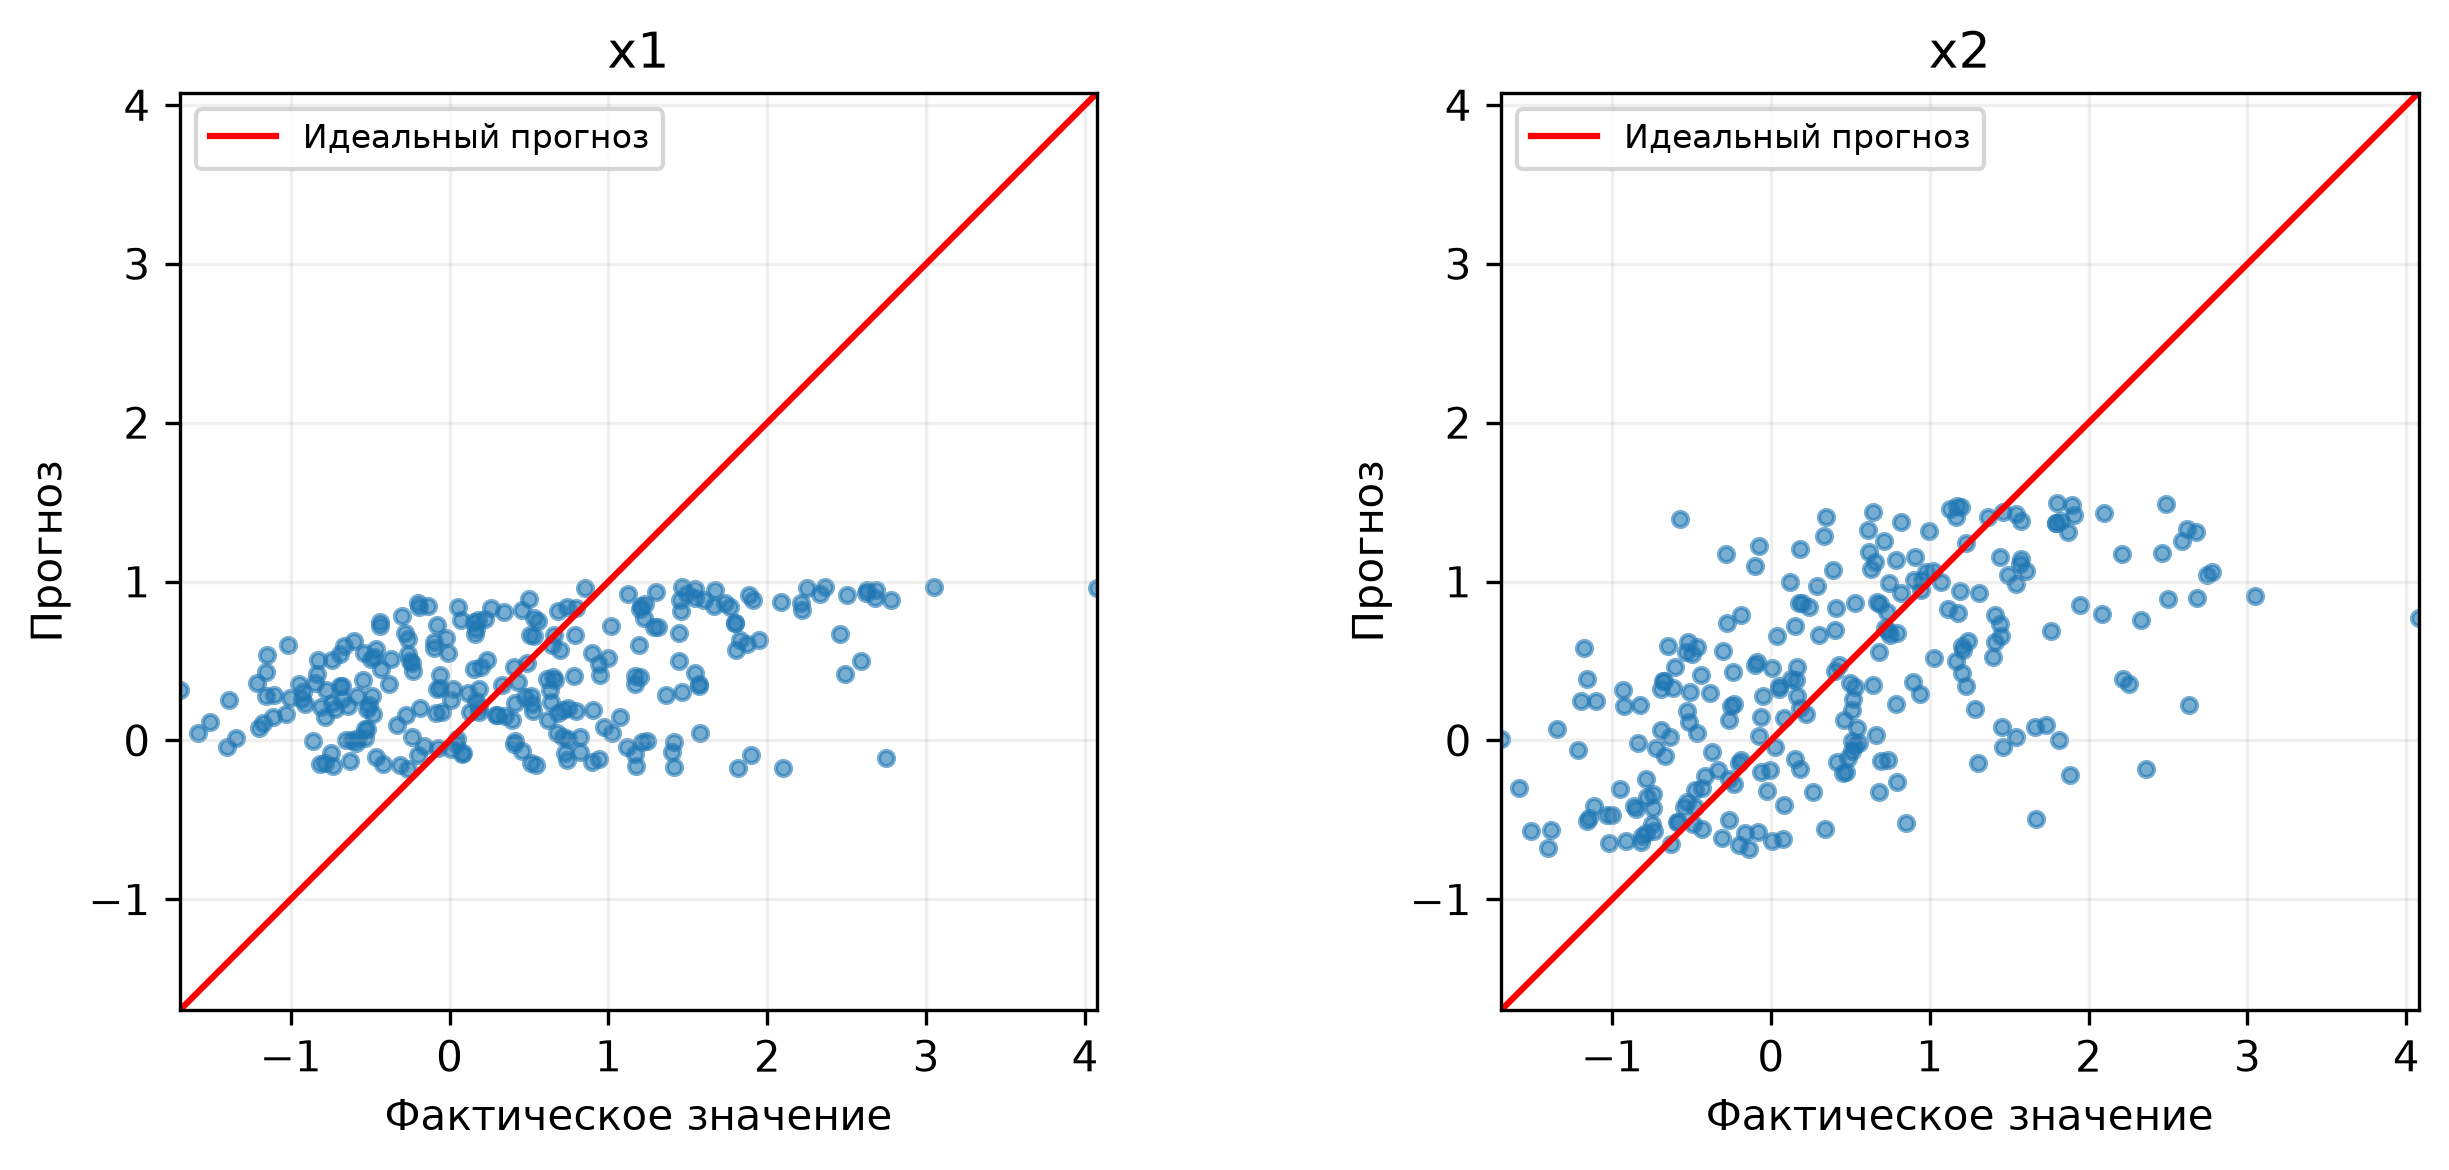

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, feature in zip(axes, ['x1', 'x2']):
    grid = np.linspace(reg[feature].min(), reg[feature].max(), 300)
    ax.scatter(reg[feature], reg.y, s=8, alpha=0.35, label='Наблюдения')
    ax.plot(grid, simple_models[feature].predict(pd.DataFrame({feature: grid})), color='red', label='Линейная модель')
    ax.set(xlabel=feature, ylabel='y', title=f'Регрессия y по {feature}')
    ax.legend()
fig.tight_layout()
savefig('01_simple_lines.png')

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for ax, feature in zip(axes, ['x1', 'x2']):
    error = simple_predictions[feature] - simple_predictions.y
    ax.plot(np.arange(1, len(error) + 1), error.to_numpy(), linewidth=0.7)
    ax.axhline(0, color='red', linewidth=1)
    ax.set(ylabel='Прогноз − факт', title=feature)
axes[-1].set_xlabel('Номер наблюдения в проверочной выборке')
fig.tight_layout()
savefig('02_simple_errors.png')

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, feature in zip(axes, ['x1', 'x2']):
    fact_prediction(ax, simple_predictions.y, simple_predictions[feature], feature)
fig.tight_layout()
savefig('03_simple_actual.png')

# 2 Полиномиальная регрессия

Для полинома выбран x1: диаграмма рассеяния показывает изгиб зависимости, который одна прямая не описывает. Для x2 основной тренд близок к линейному. Сравниваются степени 2, 3, 5 и 10, а степень 1 служит исходным ориентиром. PolynomialFeatures создаёт степени признака без отдельного столбца единиц; свободный член задаёт LinearRegression.

Степень выбирается по средней MAE при пятикратной перекрёстной проверке только на обучающей выборке. Проверочные 250 наблюдений не участвуют в этом выборе. Затем для всех степеней показаны MAE и R² на обеих выборках.

,Степень,R2_train,R2_valid,MAE_train,MAE_valid,MAE_CV
0,1,0.09849,0.14942,0.82895,0.79922,0.83202
1,2,0.29088,0.30054,0.72472,0.73346,0.72904
2,3,0.29103,0.29872,0.72440,0.73444,0.73076
3,5,0.29575,0.30864,0.72115,0.73360,0.72863
4,10,0.29873,0.30037,0.71988,0.73618,0.73001


Степень с минимальной MAE_CV: 5


,x1,Факт,Прогноз
908,-0.46909,-1.14724,0.19929
265,-0.20761,0.19670,0.03342
627,0.15929,1.16416,-0.15681
327,0.71894,0.90556,-0.21433
244,-0.76187,-0.09743,0.39471
...,...,...,...
288,0.33840,-0.92302,-0.21416
335,-0.57829,1.80301,0.27130
510,-0.06905,1.54253,-0.04684
836,0.82722,0.29990,-0.17851


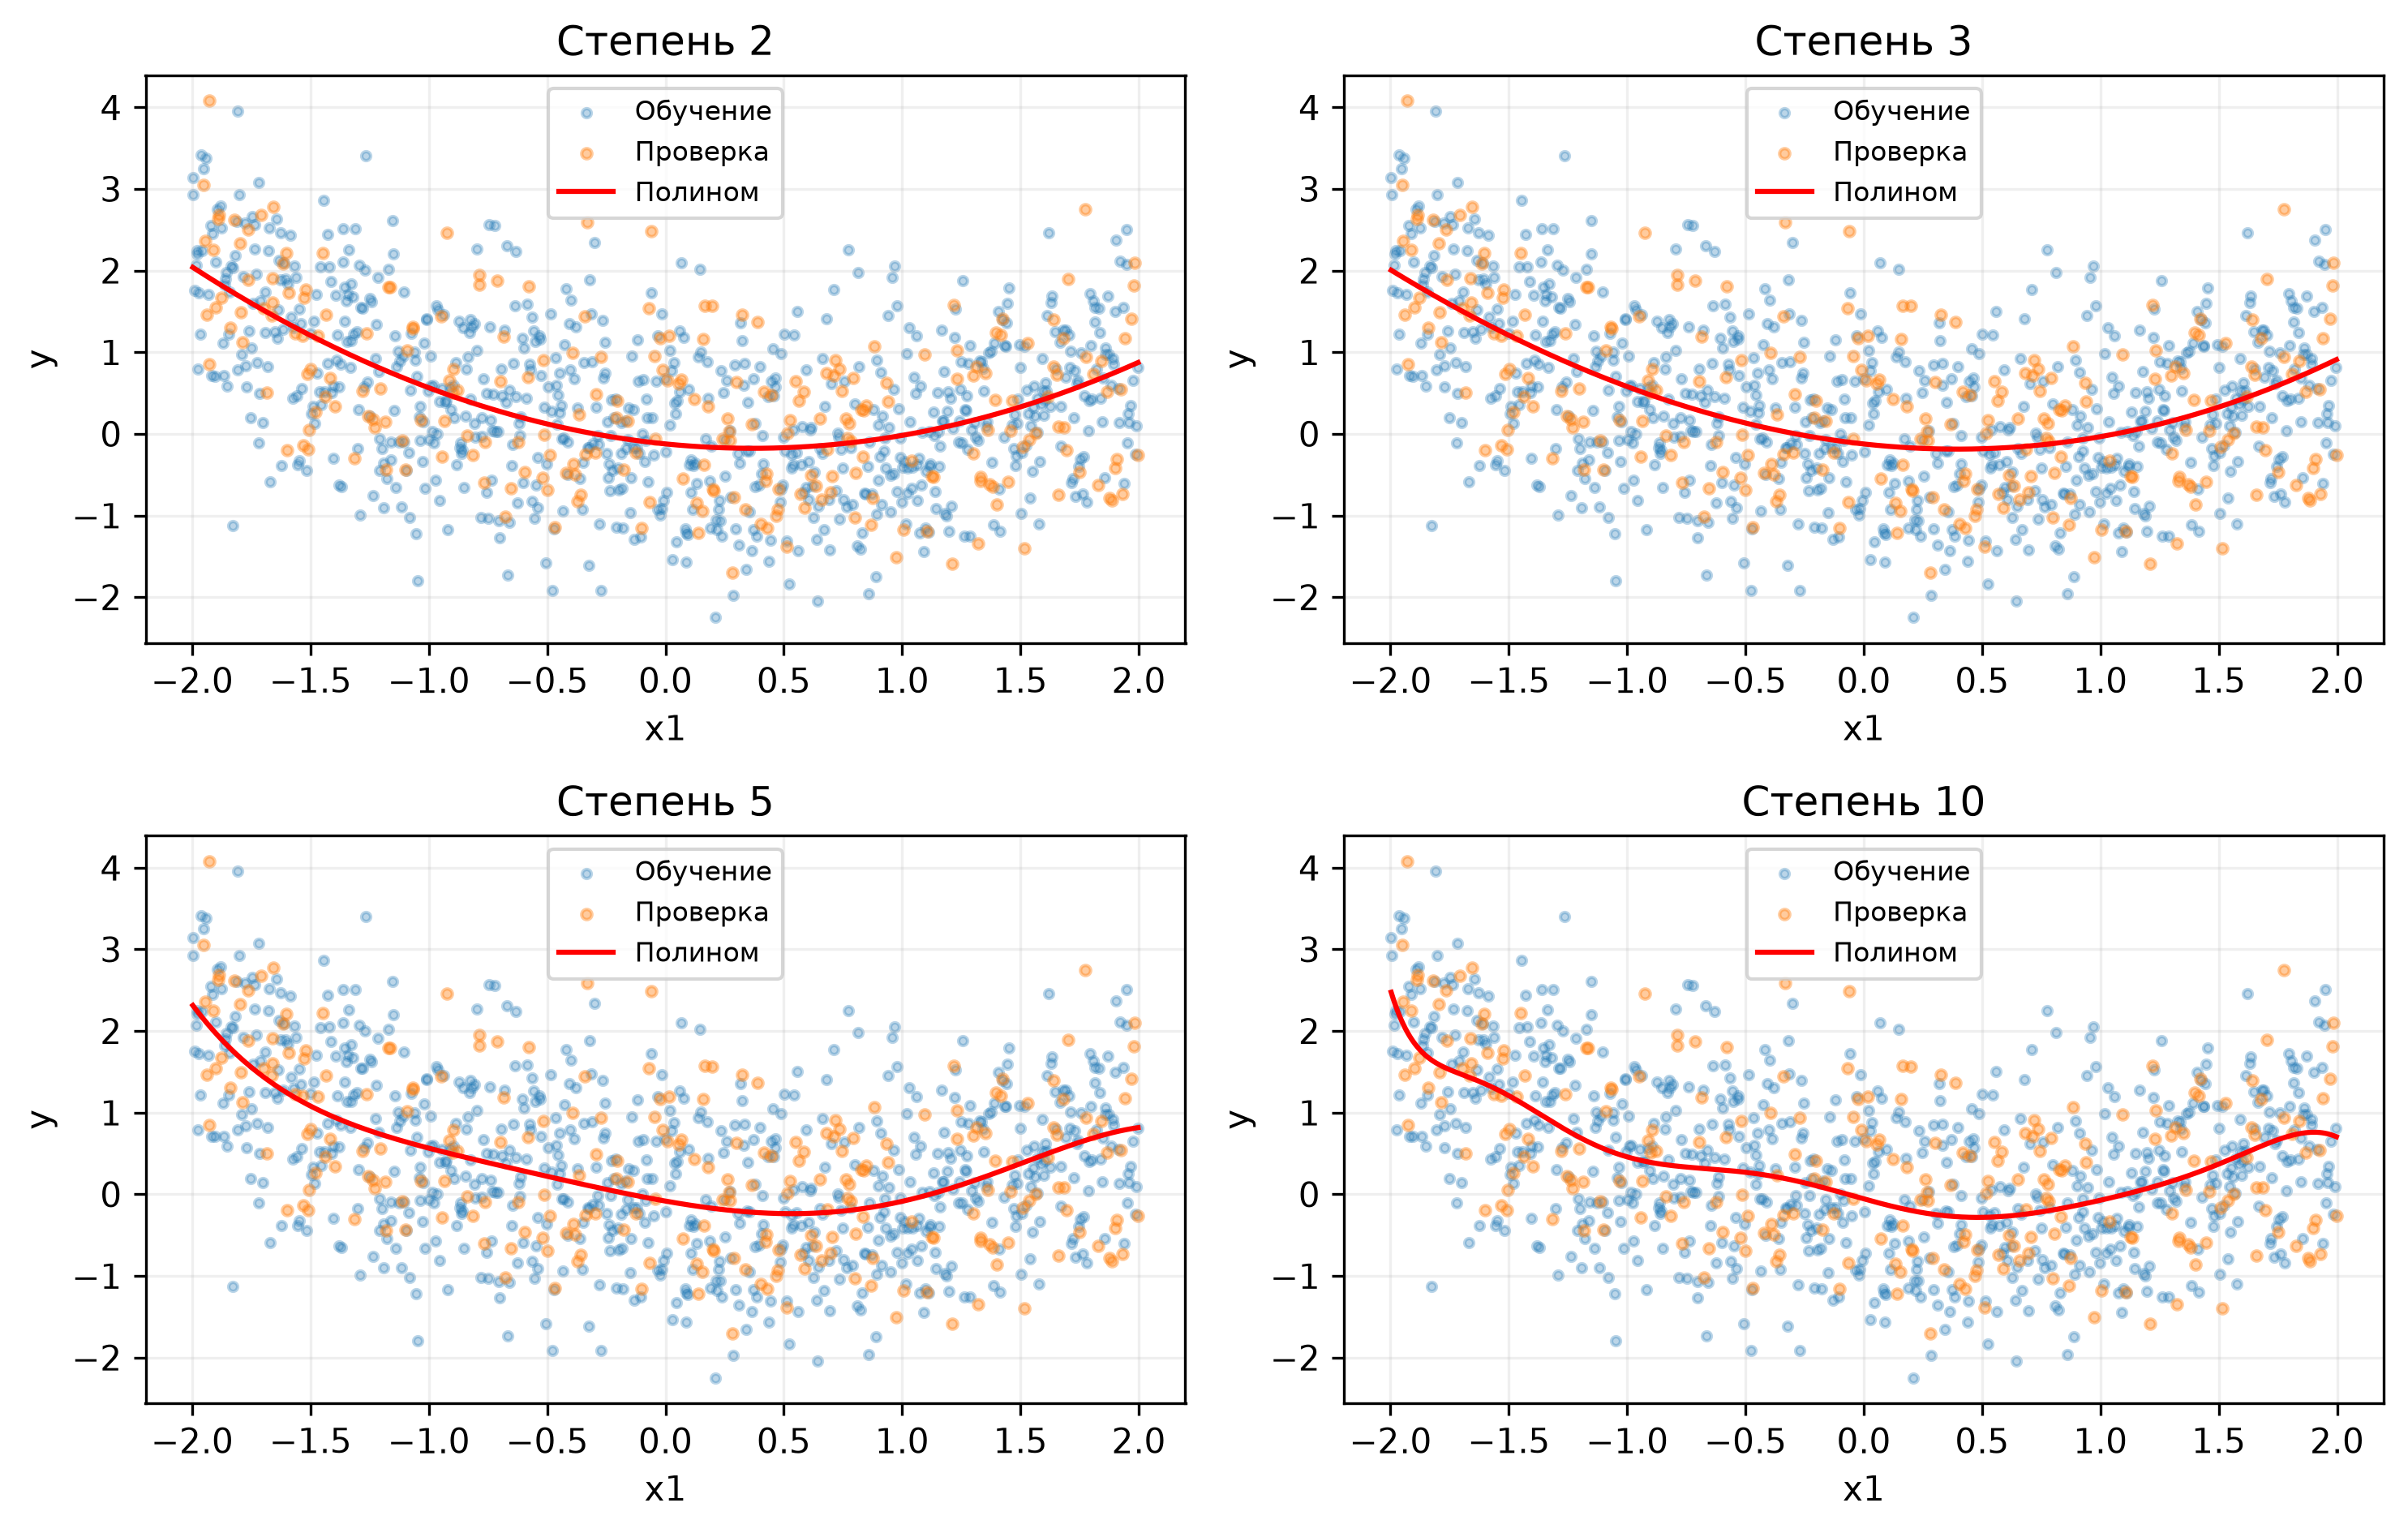

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
poly_rows = []
poly_models = {}
for degree in [1, 2, 3, 5, 10]:
    model = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), StandardScaler(), LinearRegression())
    cv_mae = -cross_val_score(model, reg.loc[train_idx, ['x1']], reg.loc[train_idx, 'y'], cv=cv, scoring='neg_mean_absolute_error', n_jobs=1).mean()
    model.fit(reg.loc[train_idx, ['x1']], reg.loc[train_idx, 'y'])
    train_prediction = model.predict(reg.loc[train_idx, ['x1']])
    valid_prediction = model.predict(reg.loc[valid_idx, ['x1']])
    poly_models[degree] = model
    poly_rows.append({'Степень': degree, 'R2_train': r2_score(reg.loc[train_idx, 'y'], train_prediction), 'R2_valid': r2_score(reg.loc[valid_idx, 'y'], valid_prediction), 'MAE_train': mean_absolute_error(reg.loc[train_idx, 'y'], train_prediction), 'MAE_valid': mean_absolute_error(reg.loc[valid_idx, 'y'], valid_prediction), 'MAE_CV': cv_mae})
poly_metrics = pd.DataFrame(poly_rows)
best_degree = int(poly_metrics.loc[poly_metrics.MAE_CV.idxmin(), 'Степень'])
display(poly_metrics)
print('Степень с минимальной MAE_CV:', best_degree)
poly_metrics.to_csv(RES / 'polynomial_metrics.csv', index=False)
poly_prediction = poly_models[best_degree].predict(reg.loc[valid_idx, ['x1']])
poly_comparison = pd.DataFrame({'x1': reg.loc[valid_idx, 'x1'], 'Факт': reg.loc[valid_idx, 'y'], 'Прогноз': poly_prediction})
display(poly_comparison)
poly_comparison.to_csv(RES / 'polynomial_predictions.csv', index_label='Индекс')
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4))
grid = pd.DataFrame({'x1': np.linspace(reg.x1.min(), reg.x1.max(), 400)})
for ax, degree in zip(axes.flat, [2, 3, 5, 10]):
    ax.scatter(reg.loc[train_idx, 'x1'], reg.loc[train_idx, 'y'], s=7, alpha=0.3, label='Обучение')
    ax.scatter(reg.loc[valid_idx, 'x1'], reg.loc[valid_idx, 'y'], s=9, alpha=0.4, label='Проверка')
    ax.plot(grid.x1, poly_models[degree].predict(grid), color='red', label='Полином')
    ax.set(xlabel='x1', ylabel='y', title=f'Степень {degree}')
    ax.legend(fontsize=8)
fig.tight_layout()
savefig('04_polynomials.png')

Оптимальная степень определяется по данным и выбранной метрике, а не задаётся универсальным числом. Слишком низкая степень не описывает изгиб и приводит к недообучению. Слишком высокая может подстраиваться под случайный шум, повышать нестабильность коэффициентов и ухудшать прогноз вне наблюдавшегося диапазона. Само увеличение степени ещё не доказывает переобучение: вывод должен опираться на проверочные ошибки.

Минимум MAE перекрёстной проверки получен при степени 5. Её преимущество над степенью 2 составляет лишь около 0,00041, поэтому убедительного выигрыша от усложнения нет. Степень 2 остаётся практически сопоставимым более простым вариантом.

# 3 Прогноз годовой зарплаты

## 3.1 Проверка исходного набора

Целевой столбец - salary. Остальные 14 столбцов описывают возраст, предыдущий доход, опыт, тест, рабочее время, расстояние, сбережения, долги и категории сотрудников. income не является целевой переменной: это доход до текущей работы. Валюта salary в описании не указана, поэтому ошибки выражены в единицах годовой зарплаты.

,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,city,job_type,marital_status,car,remote_work,salary
0,56,70201.18968,25,87.55973,62,3.70869,25987.33405,2556.82163,PhD,Chicago,Finance,Single,Yes,Yes,106233.83348
1,69,51901.89740,39,70.80838,36,7.08279,22134.89902,725.18051,High School,Houston,Retail,Single,No,Yes,87205.29104
2,46,38605.40929,4,63.32500,77,5.12915,47106.06841,12659.35958,PhD,Los Angeles,Finance,Married,Yes,No,69369.28352
3,32,49949.73696,20,78.21551,33,19.31562,15868.32881,12369.77600,Bachelor,Los Angeles,IT,Married,Yes,No,76587.11696
4,60,48965.29009,13,74.42910,48,5.65490,15734.63333,4792.09521,Bachelor,Phoenix,IT,Married,No,No,71023.14884


,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,city,job_type,marital_status,car,remote_work,salary
count,1500.00000,1500.00000,1500.00000,1500.00000,1500.00000,1500.00000,1500.00000,1500.00000,1500,1500,1500,1500,1500,1500,1500.00000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,5,5,3,2,2,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Bachelor,New York,Retail,Married,Yes,Yes,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,900,600,500,717,1050,883,NaN
mean,43.73200,50493.56217,19.47933,74.64987,49.04600,10.16917,19920.72304,7656.74931,NaN,NaN,NaN,NaN,NaN,NaN,98573.09352
std,15.07177,15354.49571,11.47153,9.90443,17.05365,10.00309,13635.53011,5481.39040,NaN,NaN,NaN,NaN,NaN,NaN,111786.75600
min,18.00000,-826.42124,0.00000,41.60500,20.00000,0.01814,408.48201,4.36713,NaN,NaN,NaN,NaN,NaN,NaN,28588.98426
25%,31.00000,40525.98972,10.00000,67.77613,34.00000,3.02216,9418.70791,3138.48422,NaN,NaN,NaN,NaN,NaN,NaN,69582.65490
50%,44.00000,50784.69057,19.00000,74.70157,49.00000,7.10517,17114.51252,6786.70378,NaN,NaN,NaN,NaN,NaN,NaN,80310.41280
75%,56.00000,61104.99796,29.00000,81.63563,63.00000,14.39207,27766.21400,11008.30957,NaN,NaN,NaN,NaN,NaN,NaN,91637.05260


Размер: (1500, 15)
Пропуски: 0
Повторы: 0
Отрицательный income: 1


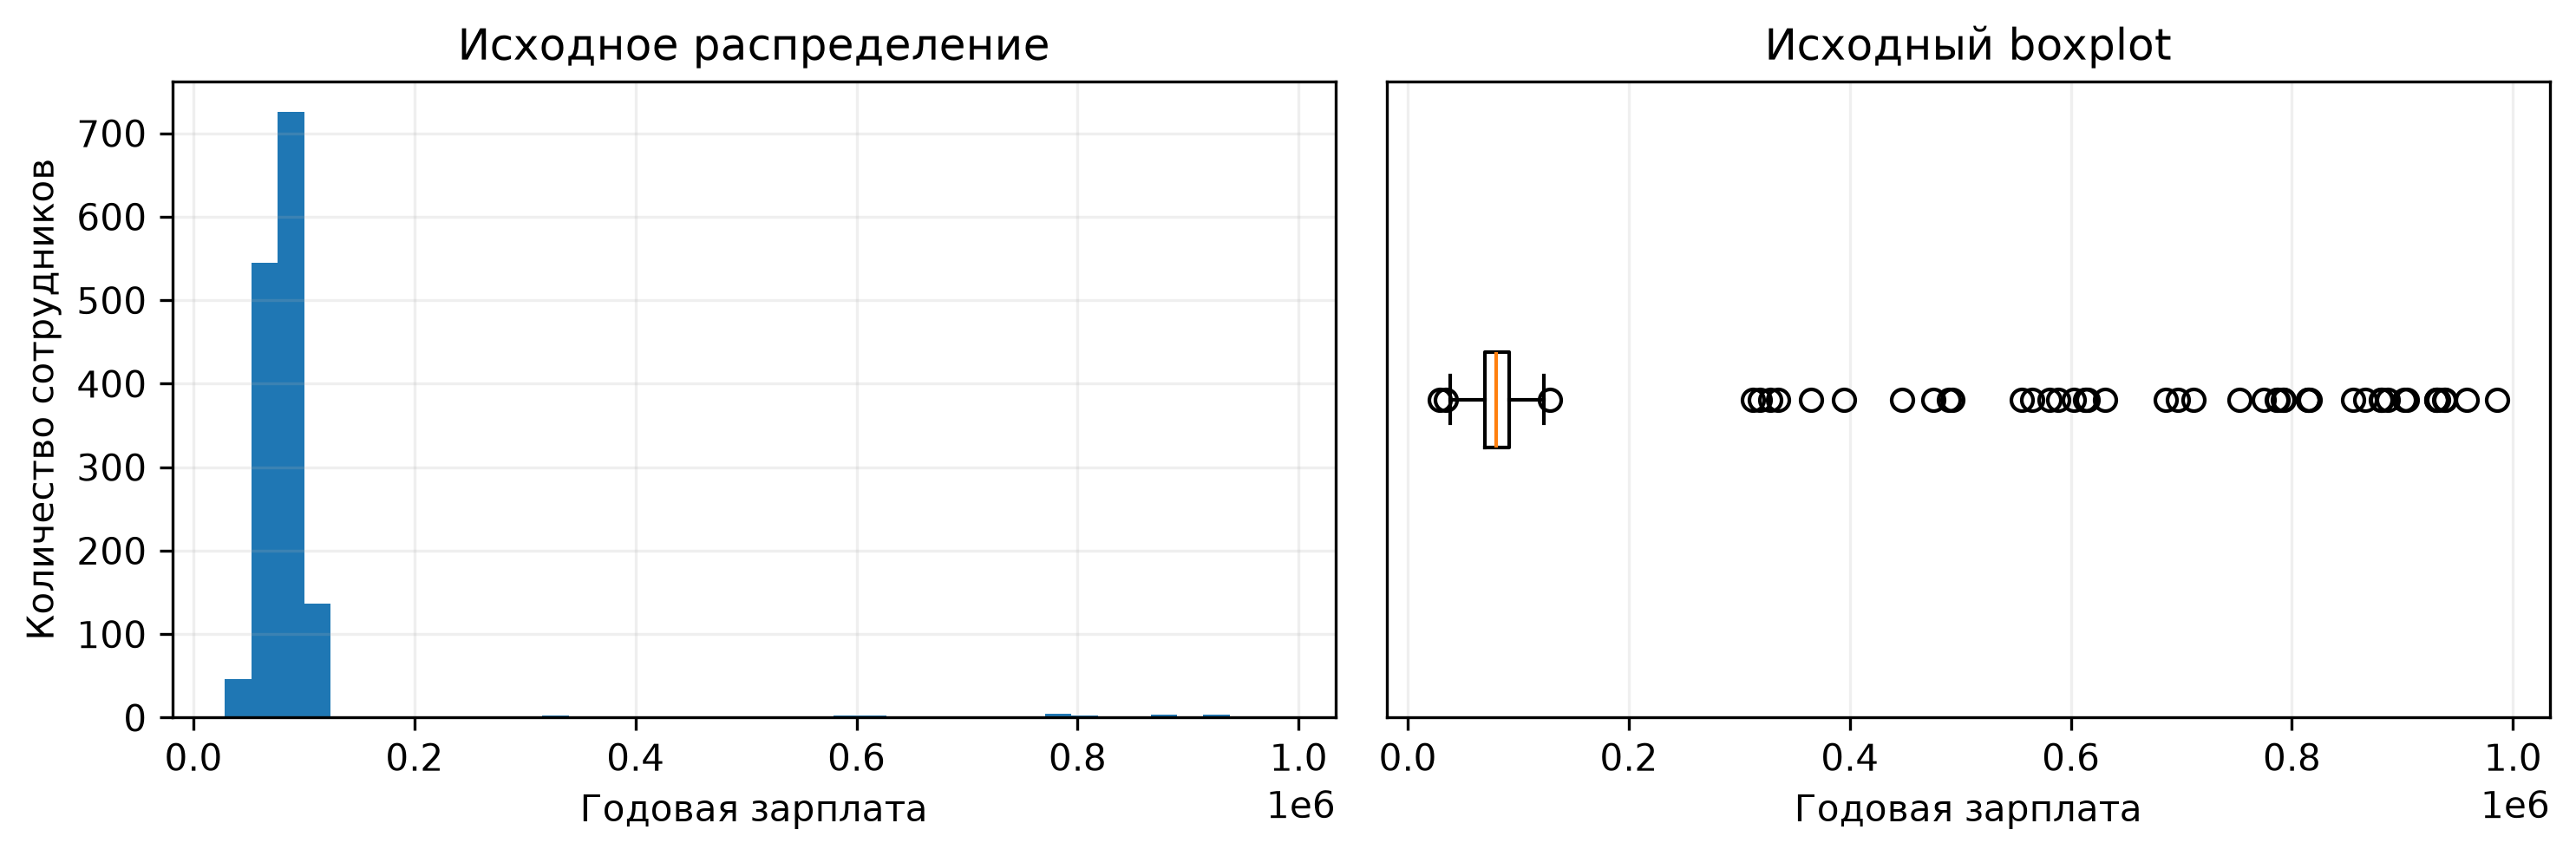

In [6]:
salary = pd.read_csv(U / 'salary.csv')
display(salary.head())
display(salary.describe(include='all'))
print('Размер:', salary.shape)
print('Пропуски:', salary.isna().sum().sum())
print('Повторы:', salary.duplicated().sum())
print('Отрицательный income:', int((salary.income < 0).sum()))
salary.describe().to_csv(RES / 'salary_describe.csv')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(salary.salary, bins=40)
axes[0].set(xlabel='Годовая зарплата', ylabel='Количество сотрудников', title='Исходное распределение')
axes[1].boxplot(salary.salary, orientation='horizontal')
axes[1].set(xlabel='Годовая зарплата', title='Исходный boxplot', yticks=[])
fig.tight_layout()
savefig('05_salary_raw.png')

## 3.2 Разбиение и обработка

Пропусков и точных повторов нет. Одно отрицательное значение income заменено на пропуск; медиана для его заполнения оценивается внутри обучаемого конвейера. Для остальных числовых признаков не вводятся неподтверждённые границы: например, шкала score_test в описании не задана.

Сначала выделено 25% наблюдений для проверки. Границы salary по правилу 1,5 межквартильного размаха рассчитаны только на обучающей части. Наблюдения за этими границами исключены только из обучения. Проверочная выборка остаётся полной, включая экстремальные зарплаты. Это сохраняет честную оценку задачи на исходном распределении. Отдельно приведены условные метрики для проверочных зарплат внутри обучающих границ; они не заменяют основную оценку.

Границы: 36054.25358; 125557.88237
Обучение: 1125 → 1088; исключено 37
Проверка: 375; за границами 11


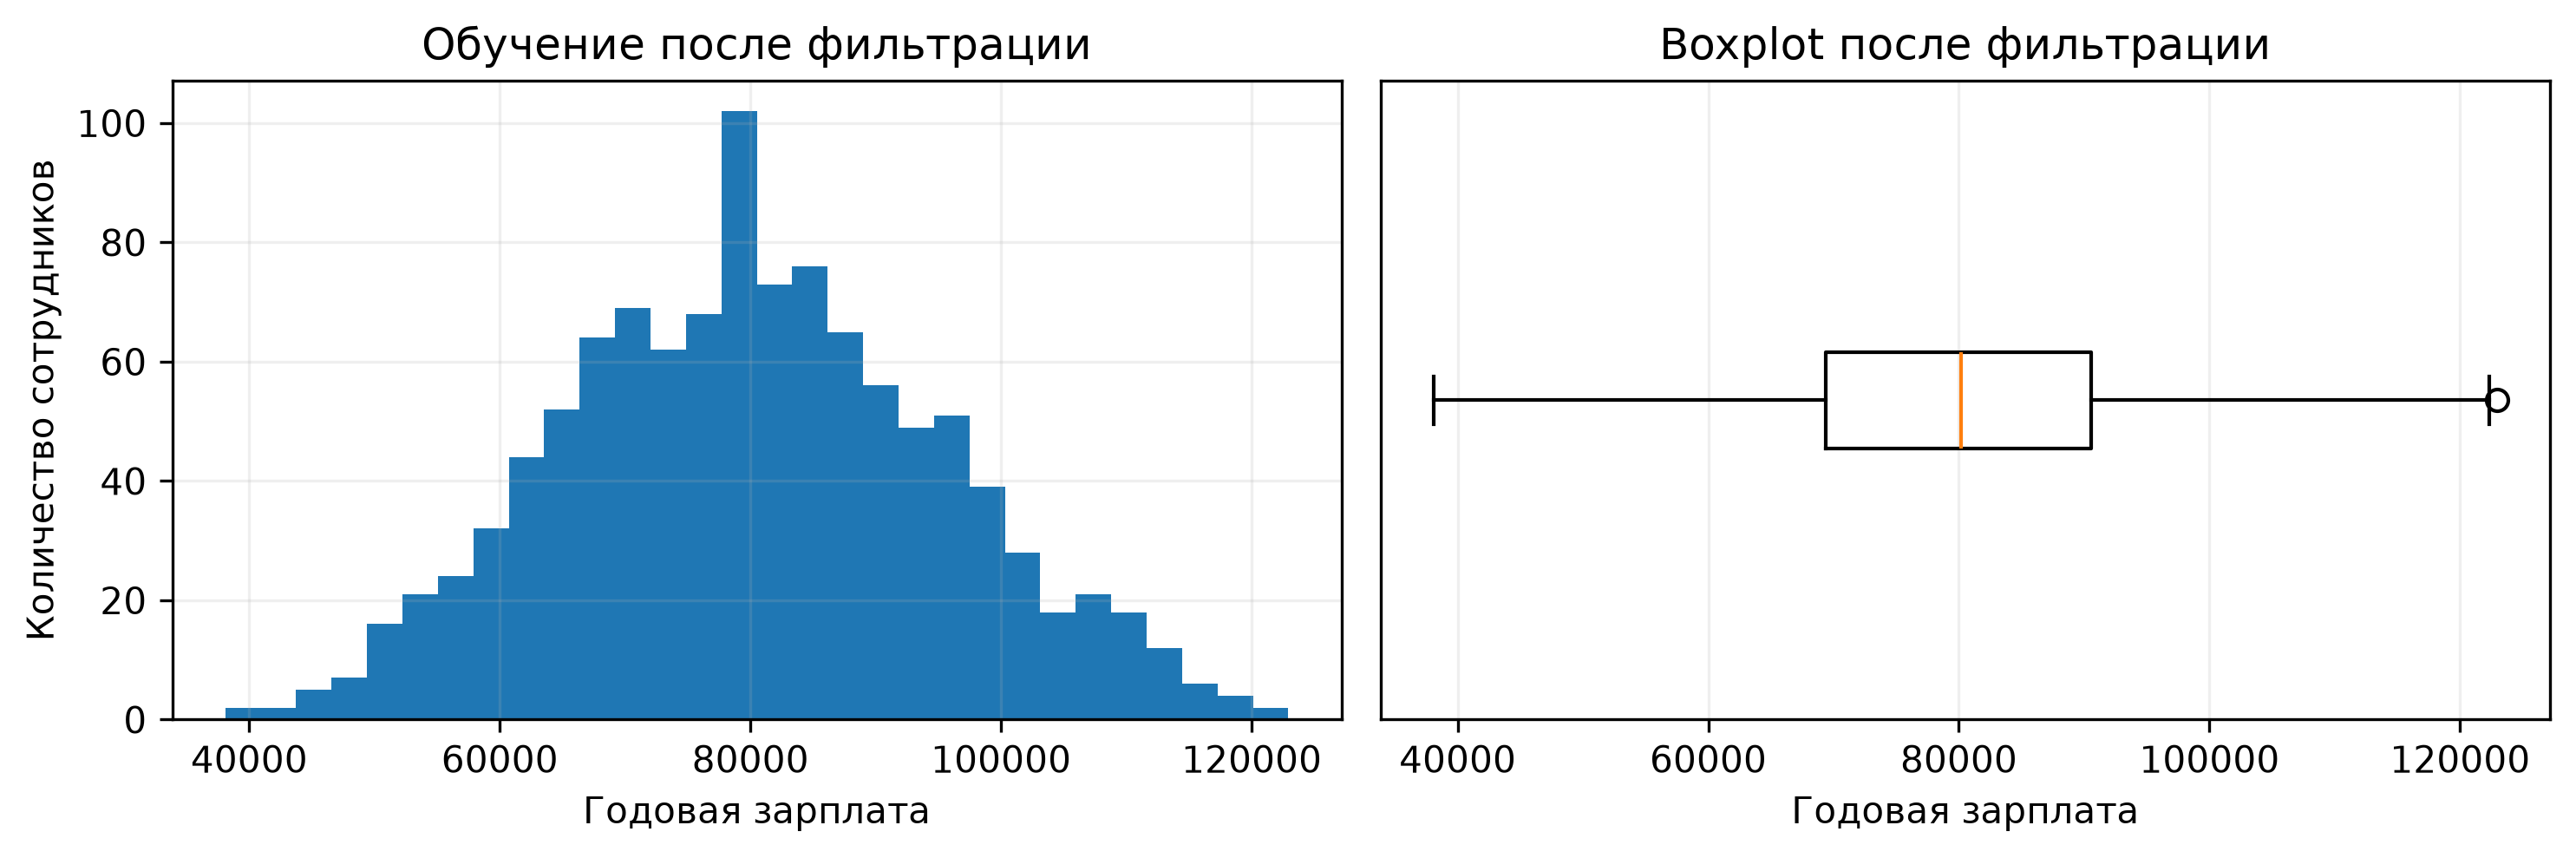

In [7]:
X = salary.drop(columns='salary').copy()
y = salary.salary.copy()
X.loc[X.income < 0, 'income'] = np.nan
X_train_raw, X_valid, y_train_raw, y_valid = train_test_split(X, y, test_size=0.25, random_state=SEED)
q1, q3 = y_train_raw.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
keep_train = y_train_raw.between(lower, upper)
keep_valid = y_valid.between(lower, upper)
X_train, y_train = X_train_raw.loc[keep_train], y_train_raw.loc[keep_train]
print(f'Границы: {lower:.5f}; {upper:.5f}')
print(f'Обучение: {len(X_train_raw)} → {len(X_train)}; исключено {int((~keep_train).sum())}')
print(f'Проверка: {len(X_valid)}; за границами {int((~keep_valid).sum())}')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(y_train, bins=30)
axes[0].set(xlabel='Годовая зарплата', ylabel='Количество сотрудников', title='Обучение после фильтрации')
axes[1].boxplot(y_train, orientation='horizontal')
axes[1].set(xlabel='Годовая зарплата', title='Boxplot после фильтрации', yticks=[])
fig.tight_layout()
savefig('06_salary_clean.png')

## 3.3 Матрица диаграмм рассеяния

Для восьми числовых предикторов и salary построена полная матрица диаграмм рассеяния на очищенной обучающей части. Диагональ содержит гистограммы. Предикторы сохраняют исходные масштабы. Связи оцениваются как наблюдаемые зависимости, без причинных выводов.

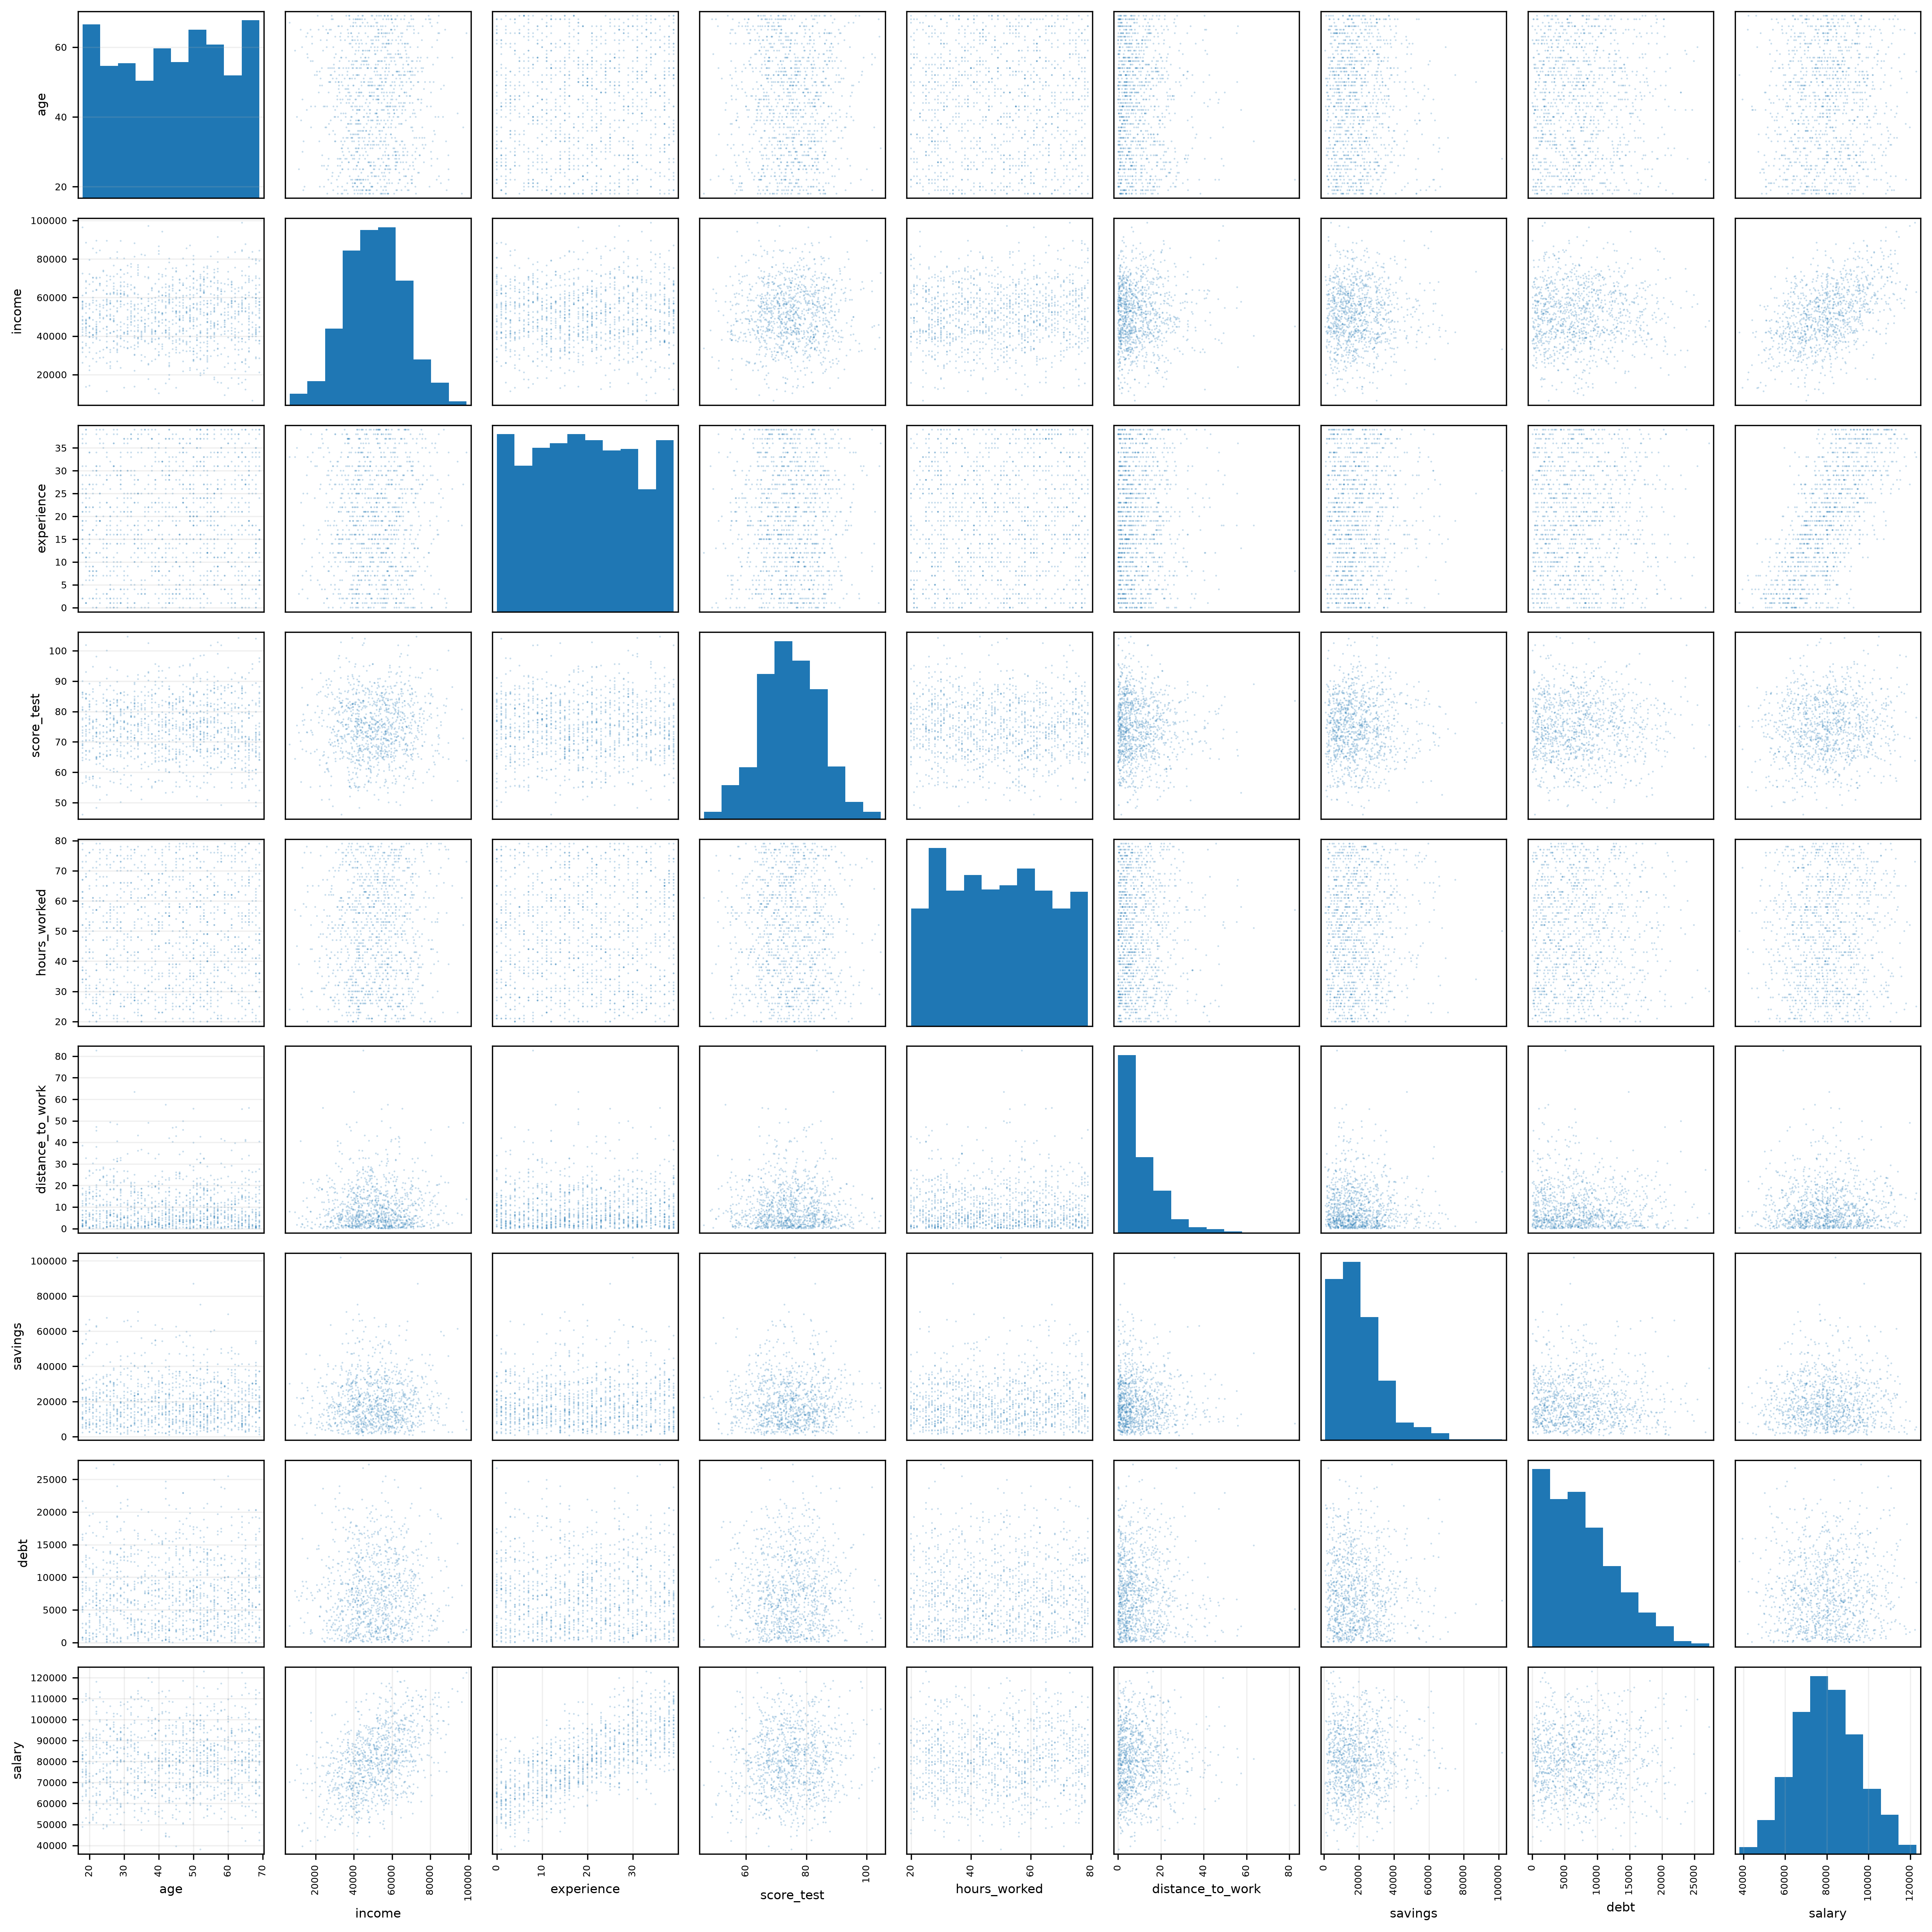

In [8]:
numeric = X.select_dtypes(include='number').columns.tolist()
categorical = X.select_dtypes(exclude='number').columns.tolist()
scatter_data = X_train[numeric].copy()
scatter_data['salary'] = y_train
axes = pd.plotting.scatter_matrix(scatter_data, figsize=(17, 17), diagonal='hist', alpha=0.25, s=5, grid=False)
for ax in axes.flat:
    ax.tick_params(labelsize=6)
    ax.xaxis.label.set_size(8)
    ax.yaxis.label.set_size(8)
plt.tight_layout()
savefig('07_scatter_matrix.png')

## 3.4 Кодирование и обучение

Числовые признаки проходят SimpleImputer(strategy='median') и StandardScaler. Категории кодируются OneHotEncoder(drop='first', handle_unknown='ignore'). Удаление базовой категории устраняет точную линейную зависимость с константой. Порядковые номера не назначаются городам и сферам работы. Образование также кодируется отдельными категориями, чтобы не навязывать равный прирост зарплаты между ступенями.

Сравниваются линейная регрессия, kNN с 5 соседями и дерево с максимальной глубиной 6 и минимумом 5 наблюдений в листе. Это заранее зафиксированные параметры, без подбора по проверочным ответам. Для масштаба ошибки добавлен постоянный прогноз медианы обучающей зарплаты. Линейная модель до фильтрации служит отдельной проверкой влияния обработки выбросов.

In [9]:
preprocess = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numeric),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical)
])
estimators = {
    'Линейная регрессия': LinearRegression(),
    'kNN': KNeighborsRegressor(n_neighbors=5, n_jobs=1),
    'Дерево решений': DecisionTreeRegressor(max_depth=6, min_samples_leaf=5, random_state=SEED)
}
salary_models = {}
salary_rows = []
central_rows = []
salary_predictions = pd.DataFrame({'Факт': y_valid})
for name, estimator in estimators.items():
    model = Pipeline([('prepare', clone(preprocess)), ('model', estimator)])
    model.fit(X_train, y_train)
    prediction = model.predict(X_valid)
    salary_models[name] = model
    salary_predictions[name] = prediction
    salary_rows.append({'Модель': name, **metrics(y_valid, prediction)})
    central_rows.append({'Модель': name, **metrics(y_valid.loc[keep_valid], prediction[keep_valid.to_numpy()])})
    comparison = pd.DataFrame({'Факт': y_valid, 'Прогноз': prediction, 'Прогноз минус факт': prediction - y_valid})
    display(Markdown(f'### {name}'))
    display(comparison)

unfiltered = Pipeline([('prepare', clone(preprocess)), ('model', LinearRegression())])
unfiltered.fit(X_train_raw, y_train_raw)
unfiltered_prediction = unfiltered.predict(X_valid)
baseline_prediction = np.full(len(y_valid), y_train.median())
salary_rows.append({'Модель': 'Линейная до фильтрации', **metrics(y_valid, unfiltered_prediction)})
salary_rows.append({'Модель': 'Медиана обучения', **metrics(y_valid, baseline_prediction)})
salary_metrics = pd.DataFrame(salary_rows)
central_metrics = pd.DataFrame(central_rows)
display(salary_metrics)
display(Markdown('Условная оценка внутри обучающих границ salary'))
display(central_metrics)
salary_metrics.to_csv(RES / 'salary_metrics.csv', index=False)
central_metrics.to_csv(RES / 'salary_central_metrics.csv', index=False)
salary_predictions.to_csv(RES / 'salary_predictions.csv', index_label='Индекс')

### Линейная регрессия

,Факт,Прогноз,Прогноз минус факт
1237,83805.26117,82062.22552,-1743.03565
437,74046.77847,73763.88273,-282.89574
51,92644.34927,90192.99166,-2451.35761
579,78156.90694,87180.68130,9023.77436
238,92794.11330,88387.84897,-4406.26433
...,...,...,...
577,90997.34598,90890.66139,-106.68459
1207,90891.08574,99967.05684,9075.97110
506,93517.12909,96112.08577,2594.95668
1154,66397.32236,61763.94964,-4633.37271


### kNN

,Факт,Прогноз,Прогноз минус факт
1237,83805.26117,84898.18148,1092.92031
437,74046.77847,77318.94468,3272.16621
51,92644.34927,88036.33218,-4608.01708
579,78156.90694,78565.54438,408.63744
238,92794.11330,82436.55900,-10357.55430
...,...,...,...
577,90997.34598,87210.40219,-3786.94379
1207,90891.08574,93673.61039,2782.52465
506,93517.12909,87251.71811,-6265.41098
1154,66397.32236,65696.56376,-700.75859


### Дерево решений

,Факт,Прогноз,Прогноз минус факт
1237,83805.26117,79739.58370,-4065.67747
437,74046.77847,62771.88316,-11274.89531
51,92644.34927,89744.40325,-2899.94602
579,78156.90694,84895.50863,6738.60169
238,92794.11330,93870.53122,1076.41793
...,...,...,...
577,90997.34598,84451.06905,-6546.27694
1207,90891.08574,99847.55742,8956.47167
506,93517.12909,90100.09865,-3417.03044
1154,66397.32236,62771.88316,-3625.43920


,Модель,MAE,MSE,RMSE,R2
0,Линейная регрессия,20699.02528,10953021511.22858,104656.68403,-0.00282
1,kNN,23468.53317,11039685547.93182,105069.90791,-0.01076
2,Дерево решений,22656.25285,10866842726.34834,104244.14960,0.00507
3,Линейная до фильтрации,36895.88371,11281109488.20017,106212.56747,-0.03286
4,Медиана обучения,27628.01047,11161887266.51880,105649.83325,-0.02194


Условная оценка внутри обучающих границ salary

,Модель,MAE,MSE,RMSE,R2
0,Линейная регрессия,4888.20241,35850364.85077,5987.51742,0.83460
1,kNN,7666.45642,92950315.47360,9641.07439,0.57117
2,Дерево решений,6998.76711,76051790.00459,8720.76774,0.64913


## 3.5 Коэффициенты и их смысл

Коэффициент числового признака показывает изменение прогноза при увеличении признака на одно обучающее стандартное отклонение и фиксированных остальных признаках. Коэффициент категории показывает отличие от базовой категории. Эти два типа коэффициентов имеют разные основания сравнения. Большой модуль коэффициента не доказывает причинное влияние и не является универсальной мерой важности.

In [10]:
linear = salary_models['Линейная регрессия']
feature_names = linear.named_steps['prepare'].get_feature_names_out()
coefficients = pd.DataFrame({'Признак': feature_names, 'Коэффициент': linear.named_steps['model'].coef_})
coefficients['Модуль'] = coefficients['Коэффициент'].abs()
coefficients = coefficients.sort_values('Модуль', ascending=False)
display(coefficients)
print('Свободный член:', linear.named_steps['model'].intercept_)
encoder = linear.named_steps['prepare'].named_transformers_['cat']
bases = {name: str(categories[0]) for name, categories in zip(categorical, encoder.categories_)}
print('Базовые категории:', bases)
coefficients.to_csv(RES / 'salary_coefficients.csv', index=False)

,Признак,Коэффициент,Модуль
10,cat__education_PhD,12326.69575,12326.69575
2,num__experience,10438.57084,10438.57084
1,num__income,7157.78829,7157.78829
9,cat__education_Master,6427.60854,6427.60854
8,cat__education_High School,-6341.67375,6341.67375
17,cat__job_type_IT,4319.64930,4319.64930
15,cat__job_type_Finance,2986.13698,2986.13698
16,cat__job_type_Healthcare,1693.22175,1693.22175
3,num__score_test,1231.00157,1231.00157
13,cat__city_New York,966.02542,966.02542


Свободный член: 76413.41557315644
Базовые категории: {'education': 'Bachelor', 'city': 'Chicago', 'job_type': 'Education', 'marital_status': 'Divorced', 'car': 'No', 'remote_work': 'No'}


## 3.6 Сравнение прогнозов

В линейной модели среди числовых признаков наибольшие коэффициенты имеют experience (10 438,57) и income (7 157,79). Для PhD получено отличие 12 326,70 от базового Bachelor, для High School - −6 341,67. Это условные связи внутри модели, а не доказанное причинное влияние.

Первая строка графиков использует всю проверочную выборку, вторая - только зарплаты внутри обучающих границ. Выбор точек второй строки зависит от известного фактического salary и поэтому не может служить правилом отбора будущих сотрудников. Это отдельное описание типичного диапазона, а не оценка модели на всём наборе.

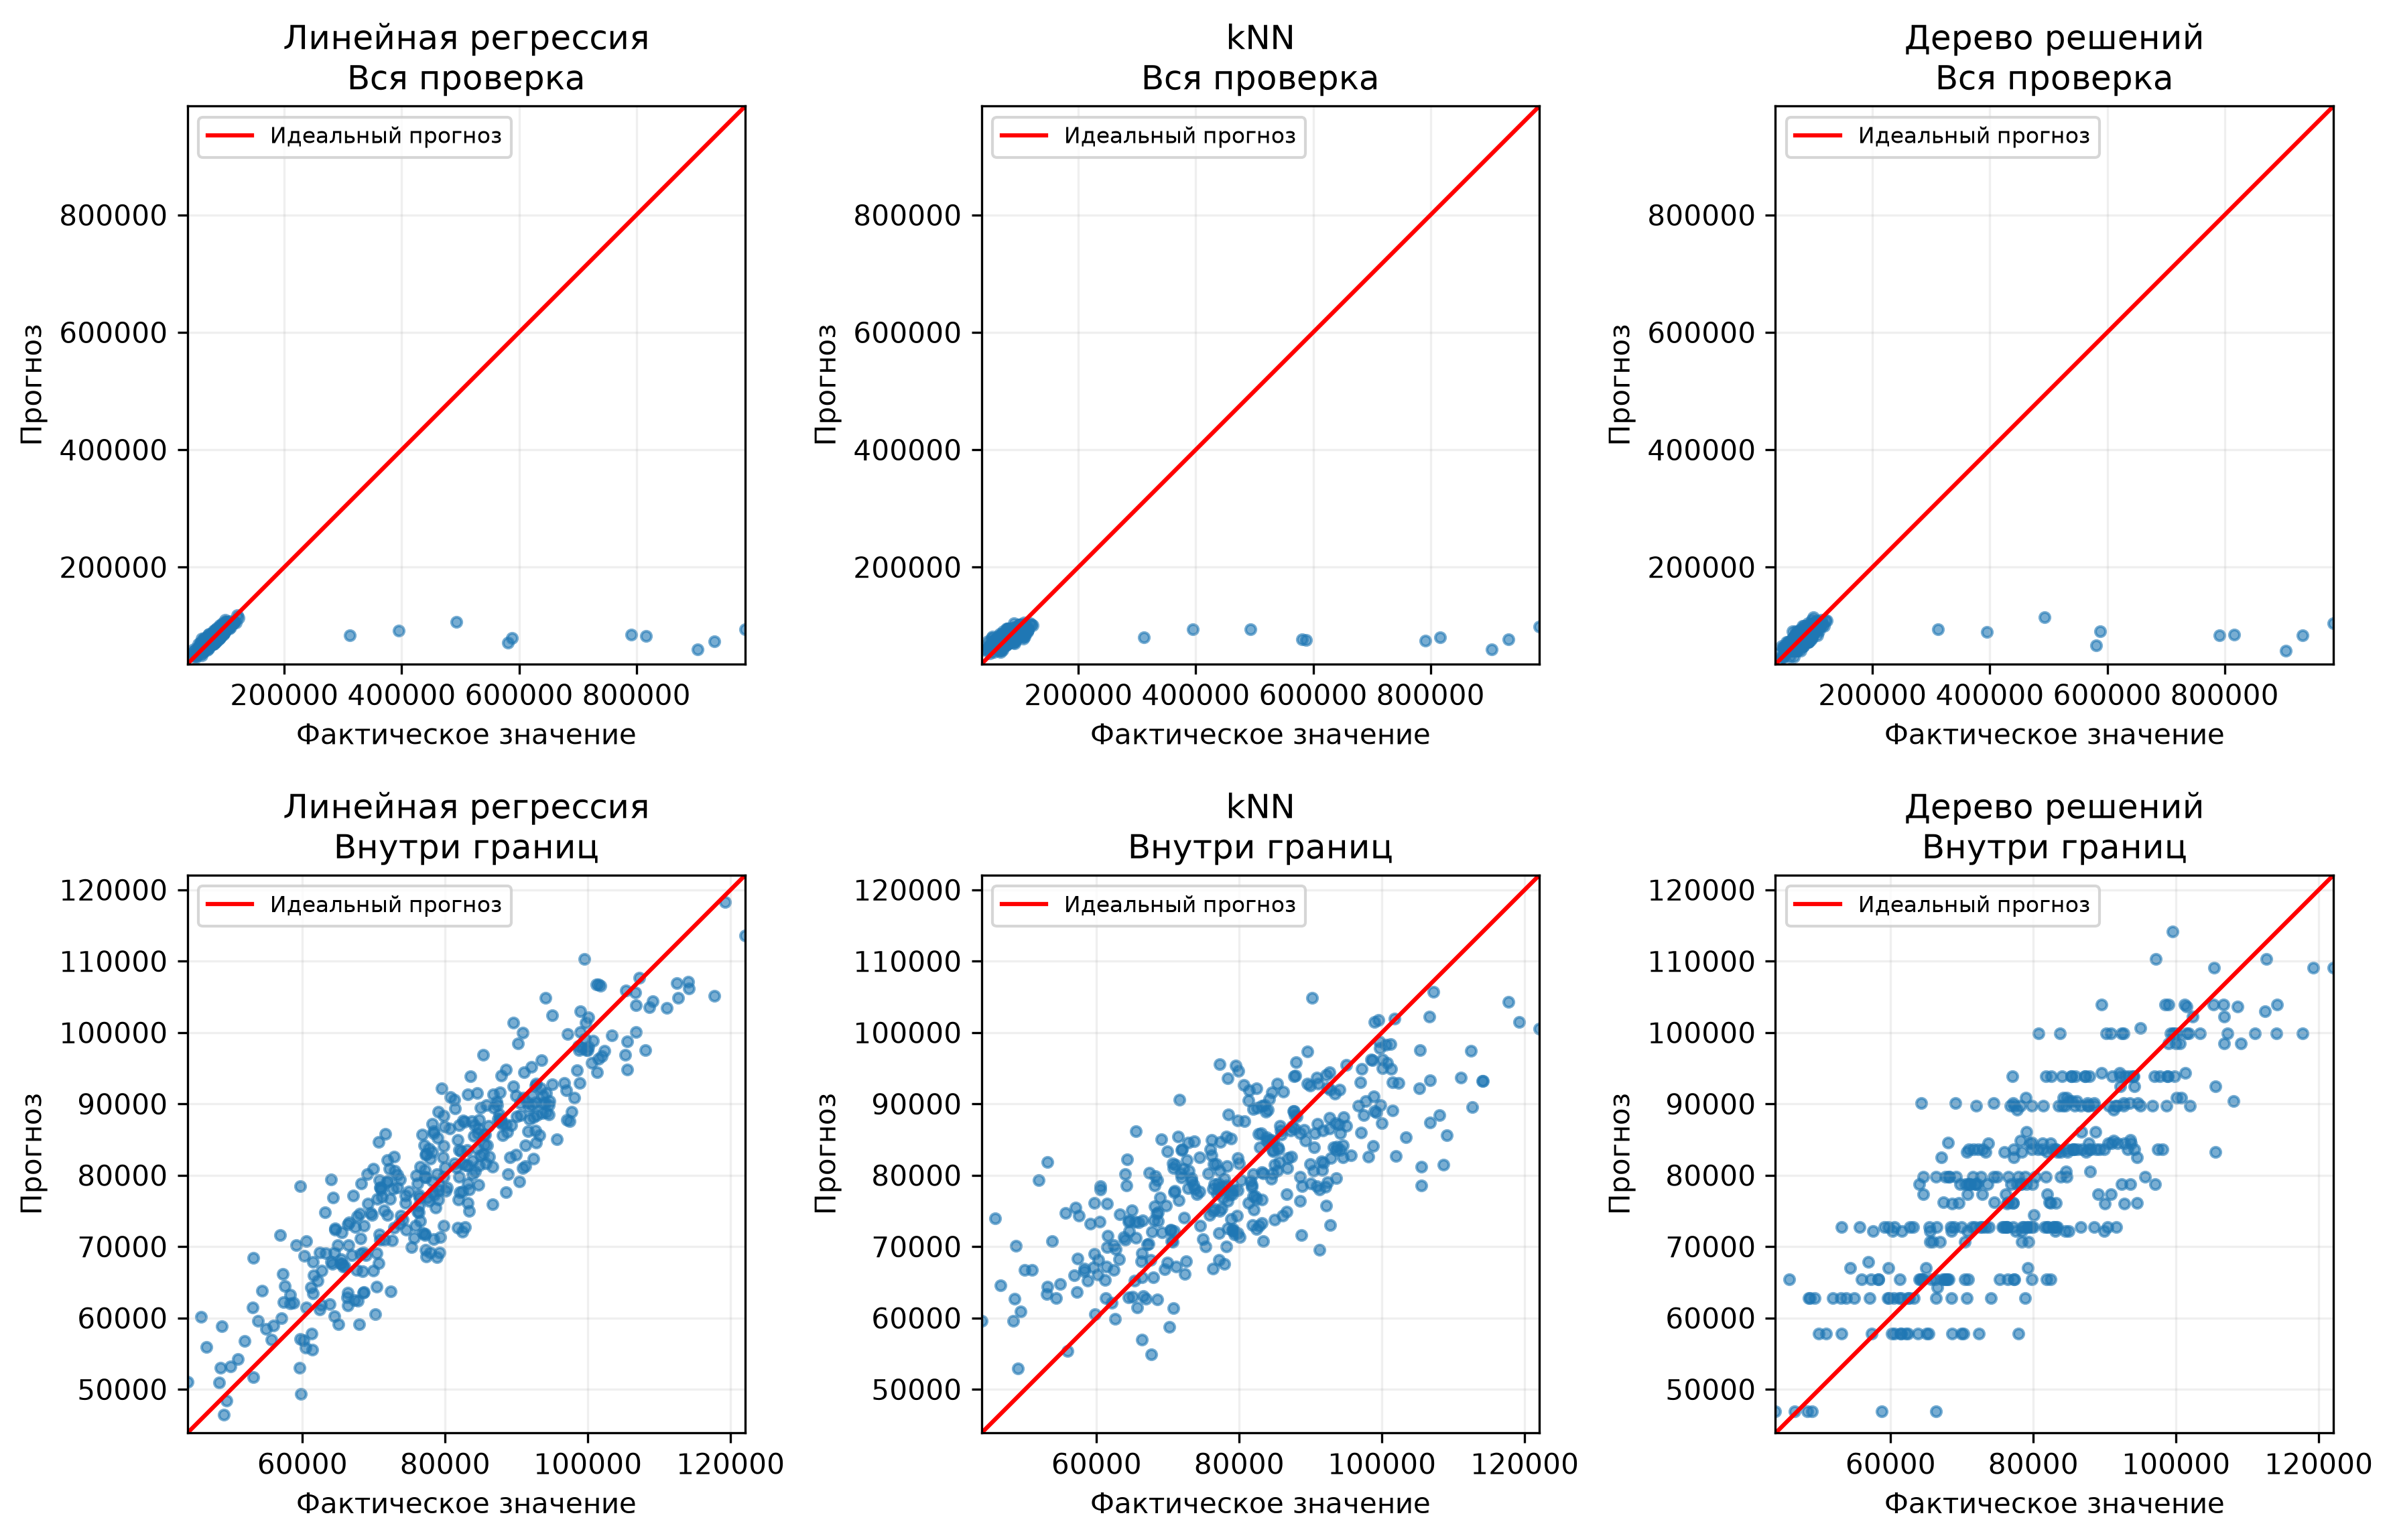

743

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7.8))
for col, name in enumerate(estimators):
    prediction = salary_predictions[name]
    fact_prediction(axes[0, col], y_valid, prediction, name + '\nВся проверка')
    fact_prediction(axes[1, col], y_valid.loc[keep_valid], prediction.loc[keep_valid], name + '\nВнутри границ')
fig.tight_layout()
savefig('08_salary_predictions.png')
summary = {
    'versions': versions, 'seed': SEED, 'regression_shape': list(reg.shape),
    'regression_train': len(train_idx), 'regression_valid': len(valid_idx),
    'best_degree': best_degree, 'salary_shape': list(salary.shape),
    'salary_train_raw': len(X_train_raw), 'salary_train': len(X_train),
    'salary_valid': len(X_valid), 'salary_valid_central': int(keep_valid.sum()),
    'salary_lower': lower, 'salary_upper': upper,
    'salary_intercept': float(linear.named_steps['model'].intercept_), 'base_categories': bases,
    'best_salary_mae': salary_metrics.iloc[:3].sort_values('MAE').iloc[0]['Модель']
}
(RES / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2))

# 4 Выводы по результатам

In [12]:
best_simple = simple_metrics.sort_values('MAE').iloc[0]
best_poly = poly_metrics.loc[poly_metrics['Степень'] == best_degree].iloc[0]
best_salary = salary_metrics.iloc[:3].sort_values('MAE').iloc[0]
display(Markdown(f"""
Для листа var8 обучены две простые линейные модели. Меньшую MAE дала модель по {best_simple['Признак']}: {best_simple['MAE']:.5f}; R² = {best_simple['R2']:.5f}. Полином по x1 степени {best_degree}, выбранный на обучающей части по MAE перекрёстной проверки, получил MAE = {best_poly['MAE_valid']:.5f} и R² = {best_poly['R2_valid']:.5f} на отложенных данных.

В salary.csv исследовано {len(salary)} сотрудников. Из обучения исключено {len(X_train_raw) - len(X_train)} экстремальных зарплат по обучающим границам IQR. Отрицательный income обработан медианным заполнением внутри конвейера. Категории закодированы, числовые признаки стандартизированы; проверочные ответы при обучении преобразований не использовались.

Среди трёх основных методов минимальную MAE на полной проверочной выборке дала модель «{best_salary['Модель']}»: {best_salary['MAE']:.2f}; RMSE = {best_salary['RMSE']:.2f}; R² = {best_salary['R2']:.5f}. Экстремальные зарплаты ухудшают квадратичные метрики, поэтому качество на центральной части рассмотрено отдельно. Результат относится к данному разбиению и не подтверждает переносимость модели на реальные кадровые данные.
"""))


Для листа var8 обучены две простые линейные модели. Меньшую MAE дала модель по x2: 0.66122; R² = 0.33495. Полином по x1 степени 5, выбранный на обучающей части по MAE перекрёстной проверки, получил MAE = 0.73360 и R² = 0.30864 на отложенных данных.

В salary.csv исследовано 1500 сотрудников. Из обучения исключено 37 экстремальных зарплат по обучающим границам IQR. Отрицательный income обработан медианным заполнением внутри конвейера. Категории закодированы, числовые признаки стандартизированы; проверочные ответы при обучении преобразований не использовались.

Среди трёх основных методов минимальную MAE на полной проверочной выборке дала модель «Линейная регрессия»: 20699.03; RMSE = 104656.68; R² = -0.00282. Экстремальные зарплаты ухудшают квадратичные метрики, поэтому качество на центральной части рассмотрено отдельно. Результат относится к данному разбиению и не подтверждает переносимость модели на реальные кадровые данные.
